In [2]:
### Find convex with moving average based on trend data (before modeling)
# 12/5
# Edit Eda_visualization.ipynb

import datetime as dt
import numpy as np
import pandas as pd

import requests
import re

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import keras
import tensorflow as tf

import pickle 
from sklearn.preprocessing import StandardScaler
from scipy.signal import savgol_filter
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.signal import argrelextrema

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM, Dense, Input, RepeatVector, TimeDistributed
from sklearn.preprocessing import MinMaxScaler

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp:  # Reads File
        return pickle.load(inp)

### EDA

In [21]:
### Visualization 2020 to 2023

df1 = read_obj("Project_final_20_23")

In [22]:
# Extract data with pt
filtered_columns = [col for col in df1.columns if ("raw" in col or "pt" in col)]

# 선택한 변수를 새로운 데이터 프레임으로 추출
df1 = df1[filtered_columns]

In [23]:
df1 = df1.diff()

In [24]:
df1['b081_raw'] = df1['b081_raw_1'] + df1['b081_raw_2']
df1 = df1.drop(['b081_raw_2', 'b081_raw_1'], axis = 1)

In [25]:
# remove spike 

df1[df1 > 1000] = None
df1[df1 < -1000] = None
df1.index = pd.to_datetime(df1.index)

In [8]:
# df1.to_csv("./CSV data/daytime_nighttime.csv")

In [12]:
def day_night_visualization(df):
    # Daytime: AM 6 ~ 18
    daytime = df.between_time('06:00', '18:00')
    nighttime = df.drop(daytime.index)
    
    # 그래프 생성
    plt.figure(figsize=(15, 6))
    plt.plot(daytime.index, daytime['b166_raw'], label='Daytime', marker='o', linestyle='none')
    plt.plot(nighttime.index, nighttime['b166_raw'], label='Nighttime', marker='o', linestyle='none')
    
    # 그래프 스타일 설정
    plt.title('Day-Night b166 Visualization')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.show()

# 함수 호출
# day_night_visualization(df1["2020-07-01 06:00:00":"2020-07-05 18:00:00"])

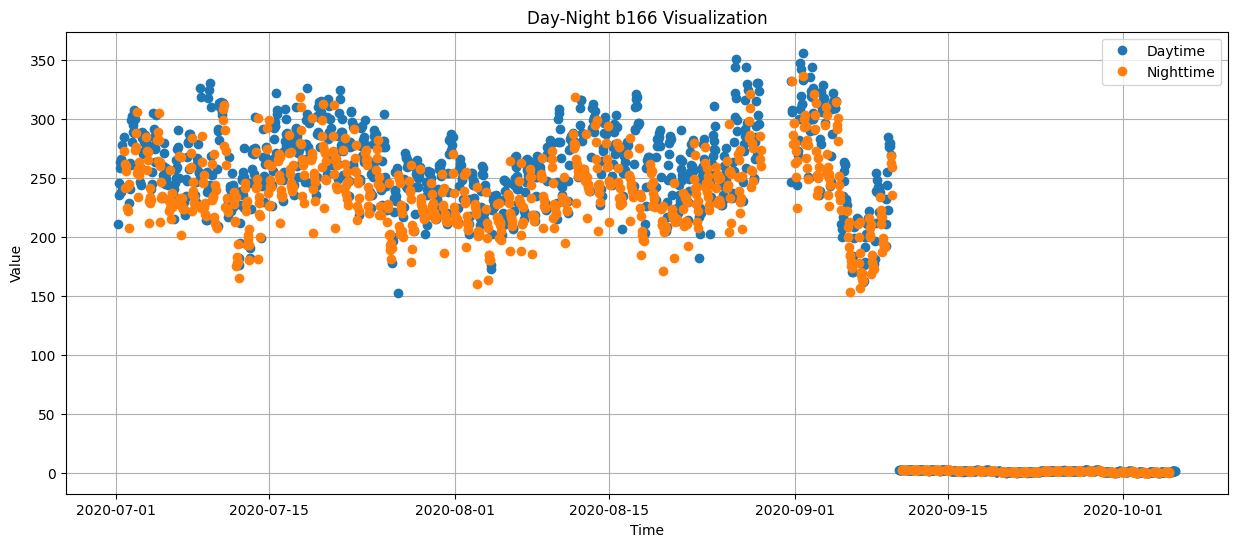

In [13]:
# 함수 호출
# df1[df1['b002_raw'] > 400] = None
day_night_visualization(df1["2020-07-01 06:00:00":"2020-10-05 18:00:00"])

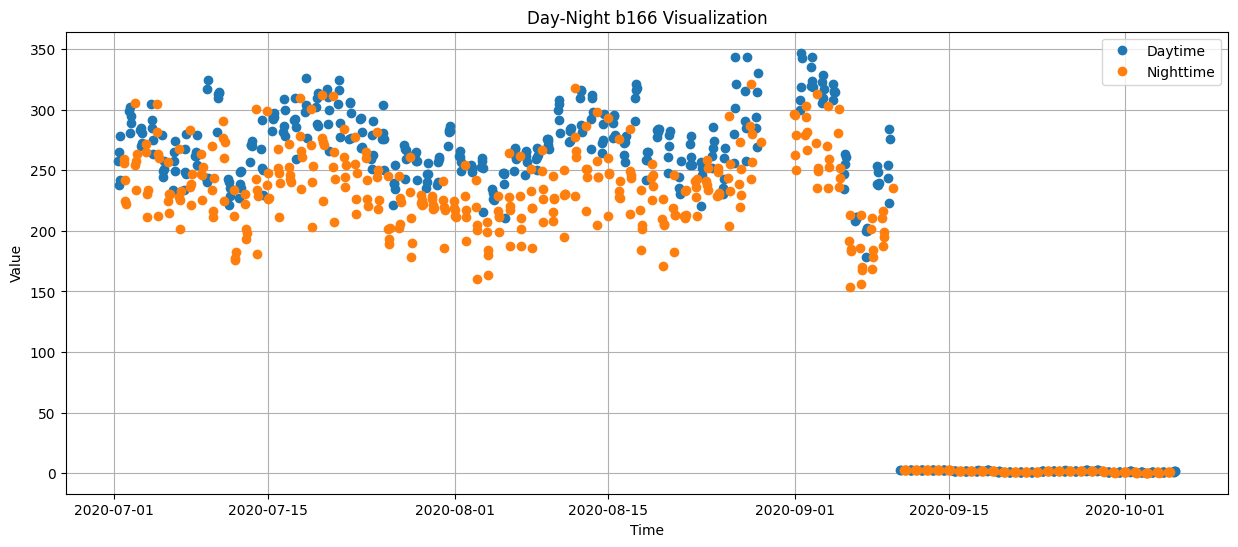

In [14]:
combined_data[combined_data['b002_raw'] > 400] = None
day_night_visualization(combined_data["2020-07-01 06:00:00":"2020-10-05 18:00:00"])

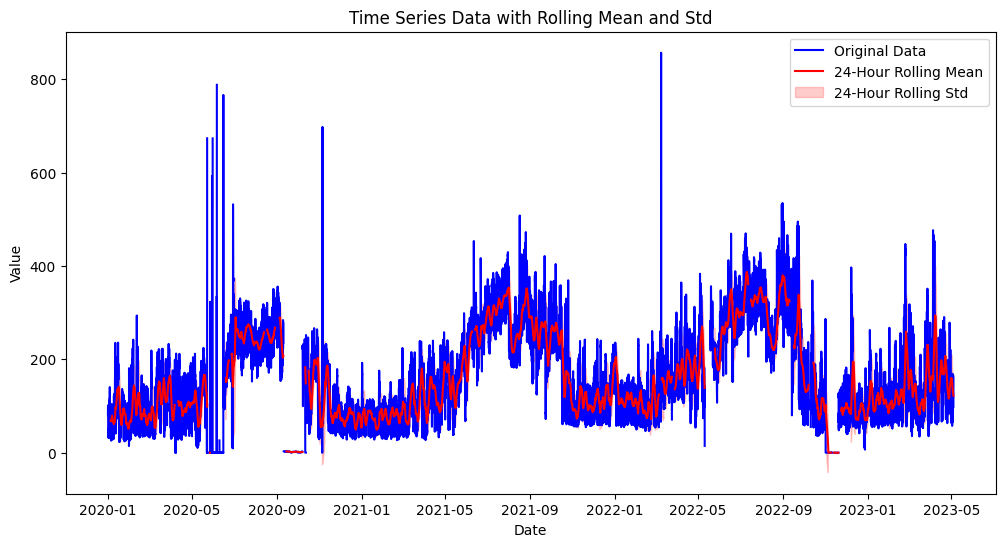

In [17]:
### Extract drift area

# 이동평균 및 이동표준편차 계산
window_size = 24 * 4 # 이동평균과 이동표준편차를 계산할 윈도우 크기
df1['rolling_mean'] = df1['b166_raw'].rolling(window=window_size).mean()
df1['rolling_std'] = df1['b166_raw'].rolling(window=window_size).std()

# 시각화
plt.figure(figsize=(12, 6))
plt.plot(df1.index, df1['b166_raw'], label='Original Data', color='blue')
plt.plot(df1.index, df1['rolling_mean'], label=f'{window_size//4}-Hour Rolling Mean', color='red')
plt.fill_between(df1.index, df1['rolling_mean'] - df1['rolling_std'], df1['rolling_mean'] + df1['rolling_std'], color='red', alpha=0.2, label=f'{window_size//4}-Hour Rolling Std')
plt.title('Time Series Data with Rolling Mean and Std')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.show()

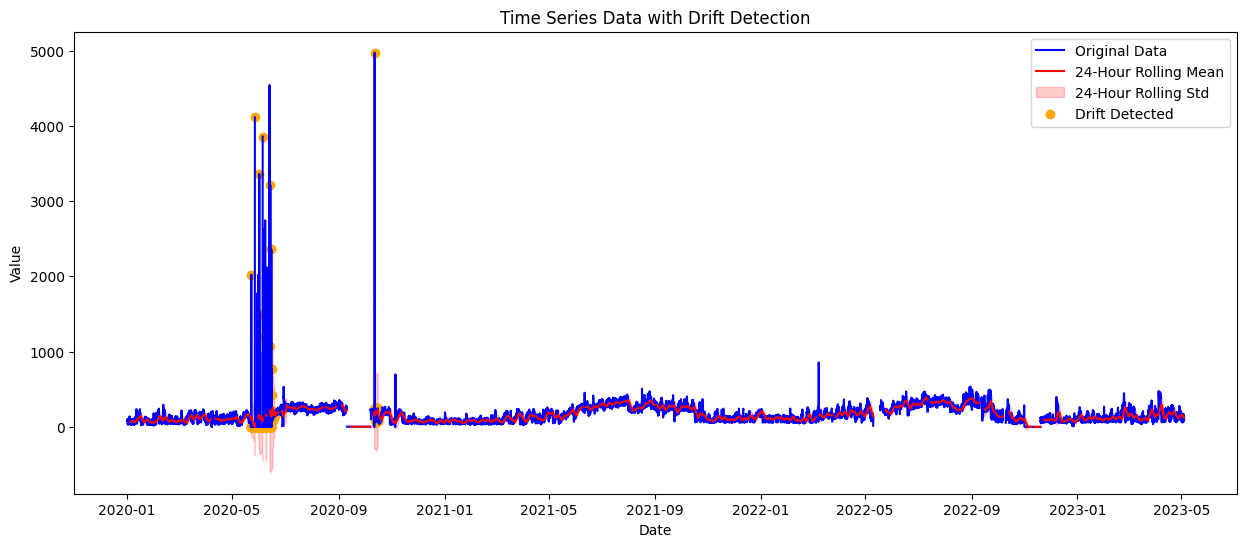

In [57]:
### visualization with threshold 

# threshold 설정
threshold = 100.0  # 임계값 설정

# Drift가 발생하는 부분 식별 with range
std_threshold = df1['rolling_std'].mean() + 2 * df1['rolling_std'].std()
drift_mask = df1['rolling_std'] > std_threshold

# 시각화
plt.figure(figsize=(15, 6))
plt.plot(df1.index, df1['b166_raw'], label='Original Data', color='blue')
plt.plot(df1.index, df1['rolling_mean'], label=f'{window_size//4}-Hour Rolling Mean', color='red')
plt.fill_between(df1.index, df1['rolling_mean'] - df1['rolling_std'], df1['rolling_mean'] + df1['rolling_std'], color='red', alpha=0.2, label=f'{window_size//4}-Hour Rolling Std')
plt.scatter(df1.index[drift_mask], df1['b166_raw'][drift_mask], color='orange', label='Drift Detected')
plt.title('Time Series Data with Drift Detection')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.show()

In [58]:
# Get shift index
drift_points = df1.index[drift_mask]
drift_points

DatetimeIndex(['2020-05-23 03:00:00', '2020-05-23 04:00:00',
               '2020-05-23 05:00:00', '2020-05-23 06:00:00',
               '2020-05-23 07:00:00', '2020-05-23 08:00:00',
               '2020-05-23 09:00:00', '2020-05-23 10:00:00',
               '2020-05-23 11:00:00', '2020-05-23 12:00:00',
               ...
               '2020-10-15 23:00:00', '2020-10-16 00:00:00',
               '2020-10-16 01:00:00', '2020-10-16 02:00:00',
               '2020-10-16 03:00:00', '2020-10-16 04:00:00',
               '2020-10-16 05:00:00', '2020-10-16 06:00:00',
               '2020-10-16 07:00:00', '2020-10-16 08:00:00'],
              dtype='datetime64[ns]', name='Date/Time', length=456, freq=None)

### Detect convex for one-day

In [9]:
df1.head()

,b210_pt,b055_raw,b103_raw,b166_raw,b002_raw,b084_raw,b081_raw
Date/Time,,,,,,,
2020-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 01:00:00,NaN,37.25,0.5,82.25,18.00,28.25,NaN
2020-01-01 02:00:00,NaN,32.50,0.5,92.25,15.75,26.75,NaN
2020-01-01 03:00:00,NaN,28.25,0.0,89.75,16.00,26.75,NaN
2020-01-01 04:00:00,NaN,32.25,0.0,84.00,15.75,26.25,NaN


In [26]:
df1 = df1.fillna(method = "ffill")
df1 = df1.fillna(method = "bfill")
df1 = df1.set_index(pd.to_datetime(df1.index))

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_52123/3118476007.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1 = df1.fillna(method = "ffill")
/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_52123/3118476007.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1 = df1.fillna(method = "bfill")


<Axes: xlabel='Date/Time'>

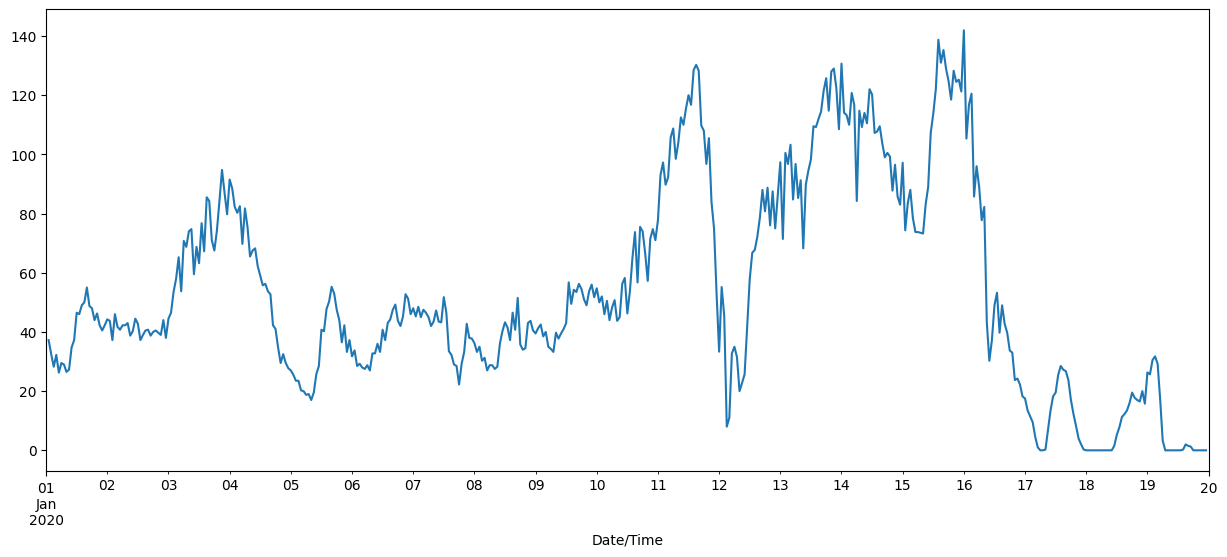

In [22]:
plt.figure(figsize = (15, 6))
df1['b055_raw']["2020-01-01 00:00:00": "2020-01-20 00:00:00"].plot()

Lowest Point on 2020-01-01: 2020-01-01 22:00:00, Window: 2020-01-01 19:00:00 to 2020-01-02 01:00:00
Lowest Point on 2020-01-02: 2020-01-02 12:00:00, Window: 2020-01-02 09:00:00 to 2020-01-02 15:00:00
Lowest Point on 2020-01-03: 2020-01-03 02:00:00, Window: 2020-01-02 23:00:00 to 2020-01-03 05:00:00
Lowest Point on 2020-01-04: 2020-01-04 17:00:00, Window: 2020-01-04 14:00:00 to 2020-01-04 20:00:00
Lowest Point on 2020-01-05: 2020-01-05 19:00:00, Window: 2020-01-05 16:00:00 to 2020-01-05 22:00:00
Lowest Point on 2020-01-06: 2020-01-06 21:00:00, Window: 2020-01-06 18:00:00 to 2020-01-07 00:00:00
Lowest Point on 2020-01-07: 2020-01-07 03:00:00, Window: 2020-01-07 00:00:00 to 2020-01-07 06:00:00
Lowest Point on 2020-01-08: 2020-01-08 22:00:00, Window: 2020-01-08 19:00:00 to 2020-01-09 01:00:00
Lowest Point on 2020-01-09: 2020-01-09 06:00:00, Window: 2020-01-09 03:00:00 to 2020-01-09 09:00:00
Lowest Point on 2020-01-10: 2020-01-10 05:00:00, Window: 2020-01-10 02:00:00 to 2020-01-10 08:00:00


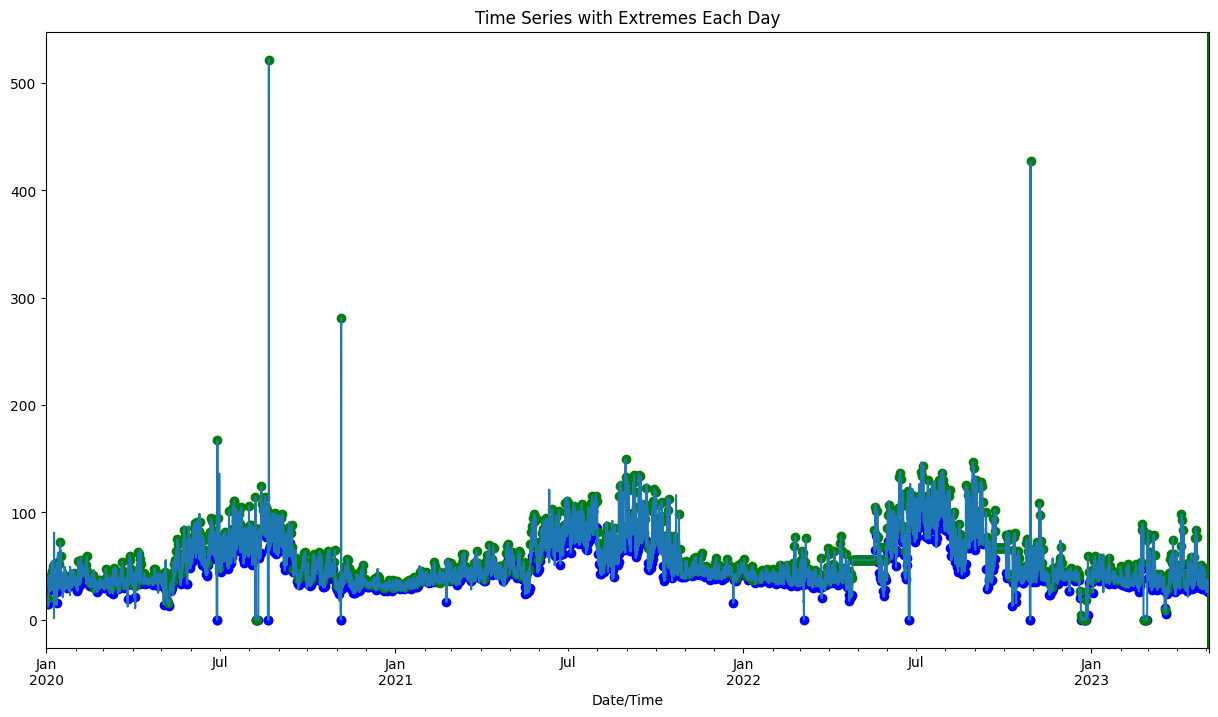

In [27]:
### Find min, max point each day

def find_extremes_each_day(df, var, window_size):
    # 날짜별로 최솟값과 최댓값을 저장할 리스트
    min_points = []
    max_points = []

    # 날짜별로 구간을 찾음
    for day, data in df.groupby(df.index.date):
        rolling_avg = data[var].rolling(window=window_size, center=True).mean()

        # 최솟값과 최댓값을 가지는 인덱스 찾기
        min_index = rolling_avg.idxmin()
        max_index = rolling_avg.idxmax()

        min_points.append((day, min_index, data[var][min_index]))
        max_points.append((day, max_index, data[var][max_index]))

    # 찾은 구간을 출력
    for point_type, points in zip(['Lowest Point', 'Highest Point'], [min_points, max_points]):
        for day, index, value in points:
            start_time = index - pd.Timedelta(hours=3)
            end_time = index + pd.Timedelta(hours=3)
            print(f"{point_type} on {day}: {index}, Window: {start_time} to {end_time}")

    # 그래프로 표시
    plt.figure(figsize=(15, 8))
    df[var].plot(label='Original Time Series')
    
    for points, color in zip([min_points, max_points], ['blue', 'green']):
        for day, index, value in points:
            plt.scatter(index, value, color=color, label=f'{day} - {point_type}')
            plt.axvspan(start_time, end_time, alpha=0.2, color=color)  # 윈도우 영역 배경색 설정


    plt.title('Time Series with Extremes Each Day')
    plt.show()

# sliding window 크기 설정 (예: 24시간)
window_size = 3

# 최솟값과 최댓값 찾기 및 그래프로 표시
find_extremes_each_day(df1, 'b002_raw', window_size)

In [28]:
df2 = df1["2020-01-01 00:00:00": "2020-01-12 23:00:00"]
# df2 = df2.drop(['rolling_mean', 'rolling_std'], axis = 1)
df2 = df2.fillna(method = "ffill")
df2 = df2.fillna(method = "bfill")
df2.dtypes
df2 = df2.reset_index()
df2 = df2.set_index(pd.to_datetime(df2['Date/Time']))
df2 = df2.drop(['Date/Time'], axis = 1)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_52123/1909240612.py:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df2 = df2.fillna(method = "ffill")
/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_52123/1909240612.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df2 = df2.fillna(method = "bfill")


In [34]:
def find_extremes_each_day2(df, var, window_size):
    # 날짜별로 최솟값과 최댓값을 저장할 리스트
    min_points = []
    max_points = []

    # 날짜별로 구간을 찾음
    for day, data in df.groupby(df.index.date):
        rolling_avg = data[var].rolling(window=window_size, center=True).mean()
        print(rolling_avg)
        # 최솟값과 최댓값을 가지는 인덱스 찾기
        min_index = rolling_avg.idxmin()
        max_index = rolling_avg.idxmax()

        min_points.append((day, min_index, data[var][min_index]))
        max_points.append((day, max_index, data[var][max_index]))

    # 찾은 구간을 출력
    for point_type, points in zip(['Lowest Point', 'Highest Point'], [min_points, max_points]):
        for day, index, value in points:
            start_time = index - pd.Timedelta(hours=3)
            end_time = index + pd.Timedelta(hours=3)
            print(f"{point_type} on {day}: {index}, Window: {start_time} to {end_time}")

    # 그래프로 표시
    plt.figure(figsize=(15, 8))
    df[var].plot(label='Original Time Series')

    for points, color in zip([min_points, max_points], ['blue', 'green']):
        for day, index, value in points:
            plt.scatter(index, value, color=color, label=f'{day} - {point_type}')
            # plt.fill_between(df.index, df[var], where=((df.index >= start_time) & (df.index <= end_time)), color=color, alpha=0.2)

    plt.title('Time Series with Extremes Each Day')
    plt.show()

Date/Time
2020-01-01 00:00:00          NaN
2020-01-01 01:00:00    17.250000
2020-01-01 02:00:00    16.583333
2020-01-01 03:00:00    15.833333
2020-01-01 04:00:00    16.083333
2020-01-01 05:00:00    15.250000
2020-01-01 06:00:00    15.250000
2020-01-01 07:00:00    14.666667
2020-01-01 08:00:00    15.333333
2020-01-01 09:00:00    15.083333
2020-01-01 10:00:00    15.166667
2020-01-01 11:00:00    16.250000
2020-01-01 12:00:00    17.833333
2020-01-01 13:00:00    20.000000
2020-01-01 14:00:00    19.250000
2020-01-01 15:00:00    19.500000
2020-01-01 16:00:00    18.750000
2020-01-01 17:00:00    18.166667
2020-01-01 18:00:00    16.666667
2020-01-01 19:00:00    14.750000
2020-01-01 20:00:00    14.916667
2020-01-01 21:00:00    14.583333
2020-01-01 22:00:00    14.333333
2020-01-01 23:00:00          NaN
Name: b002_raw, dtype: float64
Date/Time
2020-01-02 00:00:00          NaN
2020-01-02 01:00:00    14.750000
2020-01-02 02:00:00    14.416667
2020-01-02 03:00:00    14.083333
2020-01-02 04:00:00    14

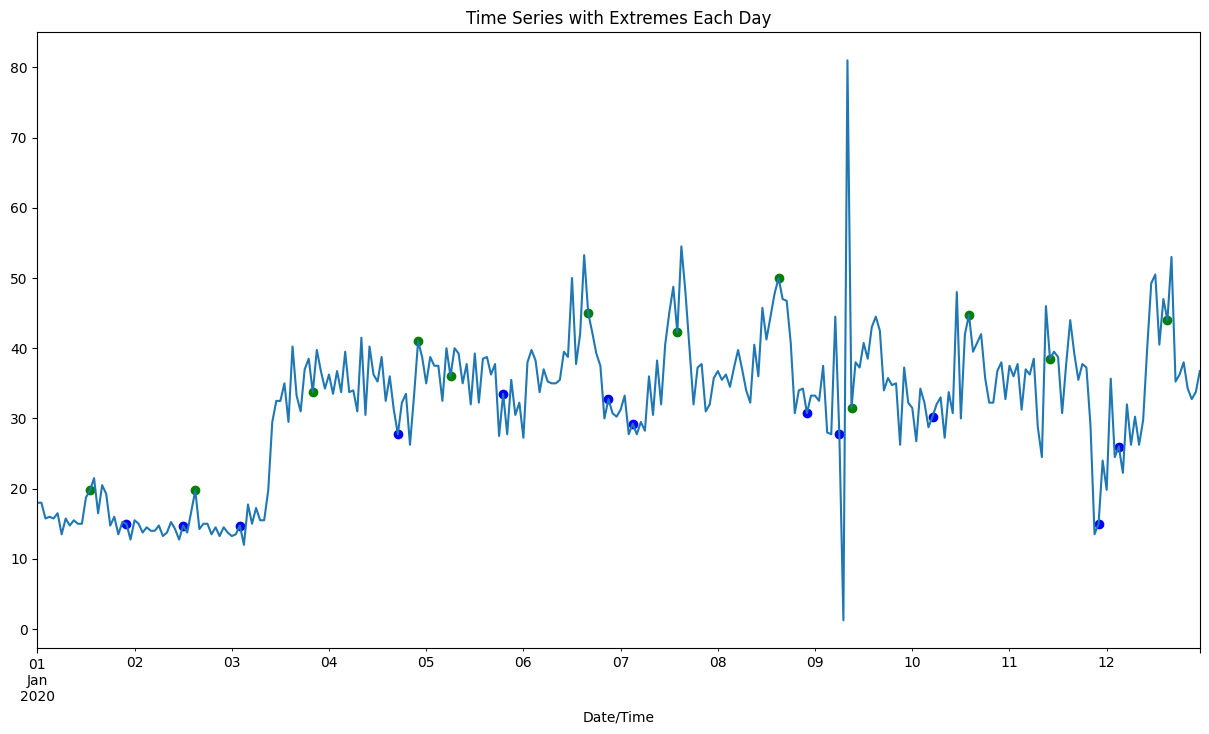

In [35]:
find_extremes_each_day2(df2, 'b002_raw', window_size)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_52123/3849644800.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['smoothed_trend'] = np.nan


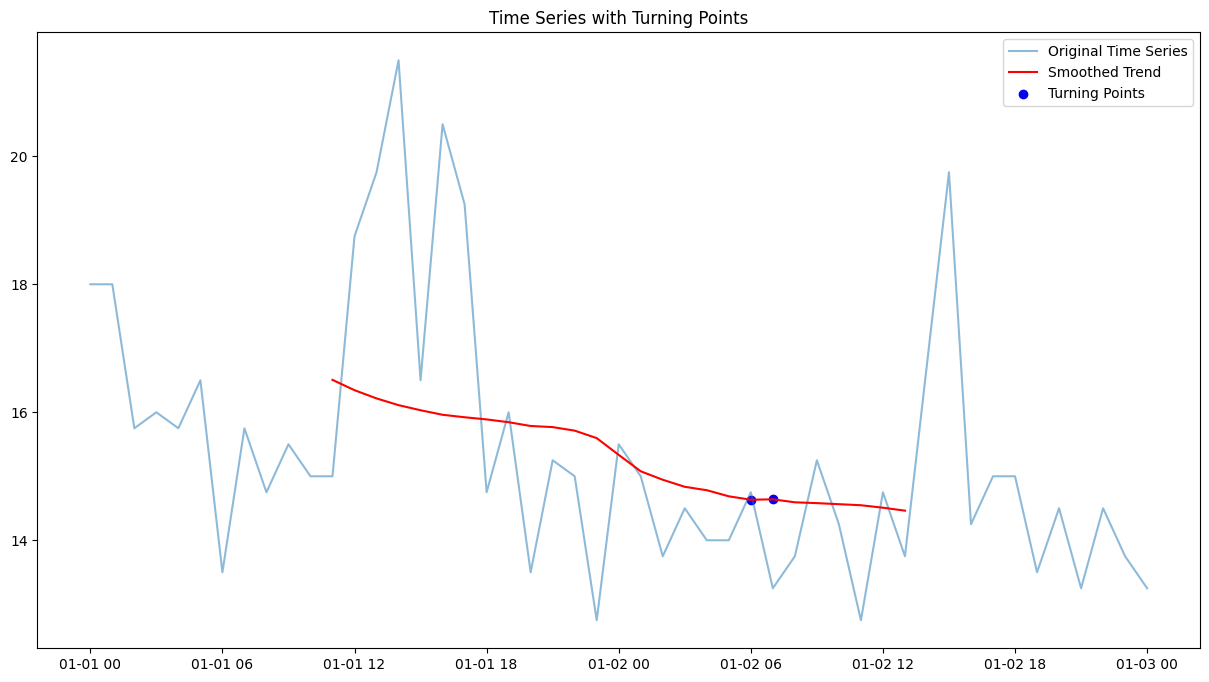

In [36]:
def find_turning_points(df, var, window_size, polyorder):
    
    # 시계열 분해를 통해 trend 추출
    result = seasonal_decompose(df[var], model='additive', period = 23)  # 주기성이 24인 경우 (하루 주기)

    # trend에 대해 데이터 스무딩 (Savitzky-Golay 필터 사용)
    smoothed_trend = savgol_filter(result.trend.dropna(), window_size, polyorder)

    # Align smoothed trend with the original time series by using interpolation
    smoothed_trend = pd.Series(smoothed_trend, index=result.trend.dropna().index)
    smoothed_trend = smoothed_trend.reindex(df.index, method='nearest')

    # Ensure both series have the same index
    df['smoothed_trend'] = np.nan
    df.loc[result.trend.dropna().index, 'smoothed_trend'] = smoothed_trend

    # Find turning points based on conditions
    turning_points = np.where(
        (df['smoothed_trend'].shift(-1) > df['smoothed_trend']) & (df['smoothed_trend'].shift(1) > df['smoothed_trend']) |
        (df['smoothed_trend'].shift(-1) < df['smoothed_trend']) & (df['smoothed_trend'].shift(1) < df['smoothed_trend'])
    )[0]
    
    # 그래프로 표시
    plt.figure(figsize=(15, 8))
    plt.plot(df.index, df[var], label='Original Time Series', alpha=0.5)
    plt.plot(df.index, df['smoothed_trend'], label='Smoothed Trend', color='red')
    plt.scatter(df.index[turning_points], df['smoothed_trend'].iloc[turning_points], color='blue', label='Turning Points')

    plt.title('Time Series with Turning Points')
    plt.legend()
    plt.show()

    return turning_points

# smoothing을 위한 window size 및 polynomial order 설정
window_size = 6
polyorder = 2

# 변곡점 찾기 및 그래프로 표시
turning_points = find_turning_points(df1["2020-01-01 00:00:00": "2020-01-03 00:00:00"], 'b002_raw', window_size, polyorder)

In [ ]:
from statsmodels.tsa.seasonal import STL

# STL 분해 수행
stl = STL(df1['b002_raw'], seasonal=13)  # seasonal 주기를 조절할 수 있습니다.
result = stl.fit()

# 변곡점 찾기
residuals = result.resid
change_points = np.where((residuals.shift(1) > 0) & (residuals < 0))[0]

# 변곡점을 기준으로 sliding window로 최대, 최소 구간 찾기
window_size = 24  # 예시로 윈도우 크기를 24로 설정합니다.
for cp in change_points:
    start = max(0, cp - window_size // 2)
    end = min(len(df1), cp + window_size // 2)
    
    # 원본 시계열에 대해 구간을 그래프로 표현
    plt.figure(figsize=(10, 4))
    plt.plot(df1.index[start:end], df1['b002_raw'][start:end], label='Original Data')
    plt.axvline(df1.index[cp], color='red', linestyle='--', label='Change Point')
    plt.title(f"Change Point Detection - Window around Change Point at {df.index[cp]}")
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()

""" 
# 시계열 분해
result = seasonal_decompose(df1['b002_raw'], model='additive', period=24)  # 24는 1일(24시간)을 의미

# 변곡점 찾기
diff = df1['b002_raw'] - result.trend
peaks = (diff > 0) & (diff.shift(-1) < 0)
valleys = (diff < 0) & (diff.shift(-1) > 0)
df1['gradient'] = df1['b002_raw'].diff()

# Sliding window를 통한 최대, 최소 구간 찾기
window_size = 24  # 예제에서는 1일(24시간)로 설정
df1['max_point'] = df1['gradient'].rolling(window=window_size).max()
df1['min_point'] = df1['gradient'].rolling(window=window_size).min()


# 변곡점을 그래프로 표현
plt.figure(figsize=(12, 6))
plt.plot(df1.index, df1['b002_raw'], label='Original Data')
plt.plot(df1.index, df1['max_point'], label='Max Point')
plt.plot(df1.index, df1['min_point'], label='Min Point')

plt.title('Time Series with Turning Points')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()
"""

### Detect Convex with window

In [78]:
def detect_turning_points(df, var, window_size = 1):
    # 시계열 분해 및 trend 추출
    trend = df[var].rolling(window=window_size, min_periods = 1, center = True).mean()

    # 변곡점 찾기
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    local_minima = argrelextrema(trend.values, np.less)[0]

    # 그래프 표시
    plt.figure(figsize=(15, 6))
    plt.plot(df.index, df[var], label='Original Data', color='blue')
    plt.plot(df.index, trend, label=f'Trend (Window Size = {window_size})', color='orange')

    # 변곡점 표시
    plt.scatter(df.index[local_maxima], trend.iloc[local_maxima], marker='o', color='red', label='Maxima')
    plt.scatter(df.index[local_minima], trend.iloc[local_minima], marker='o', color='green', label='Minima')

    # 변곡점 구간 표시
    for i in range(len(local_maxima)):
        plt.axvspan(df.index[max(0, local_maxima[i] - window_size)], df.index[local_maxima[i]], color='red', alpha=0.2)

    for i in range(len(local_minima)):
        plt.axvspan(df.index[max(0, local_minima[i] - window_size)], df.index[local_minima[i]], color='green', alpha=0.2)

    plt.title('Turning Points Detection with Trend and Windows')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
detect_turning_points(df1["2020-01-01 00:00:00": "2020-01-03 00:00:00"], 'b002_raw', window_size=12)


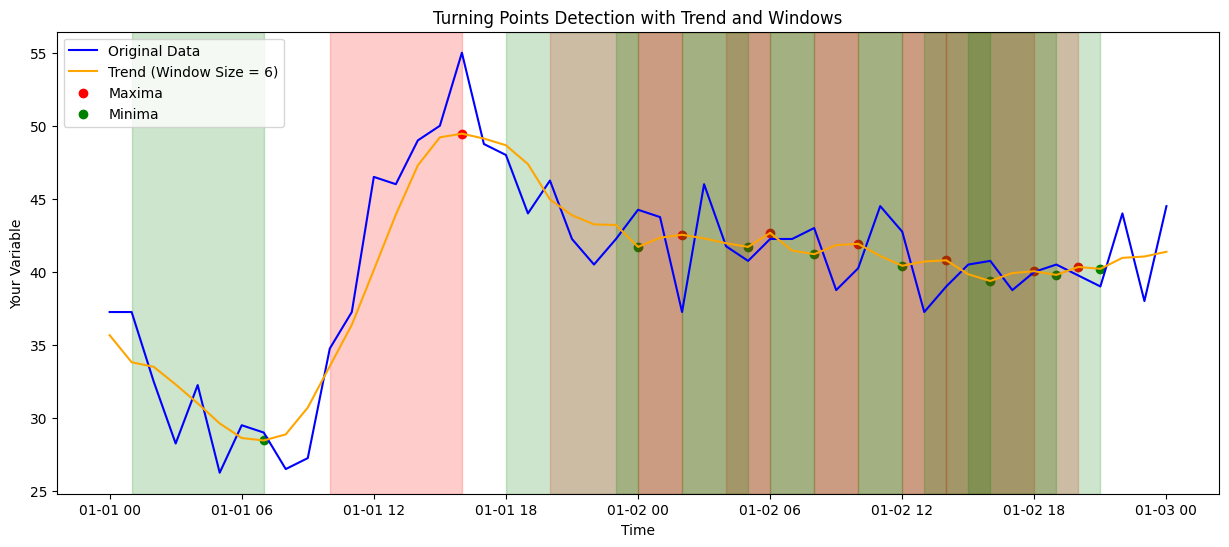

In [82]:
detect_turning_points(df1["2020-01-01 00:00:00": "2020-01-03 00:00:00"], 'b055_raw', window_size = 6)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_52123/405526212.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[:, 'date'] = df.index.date


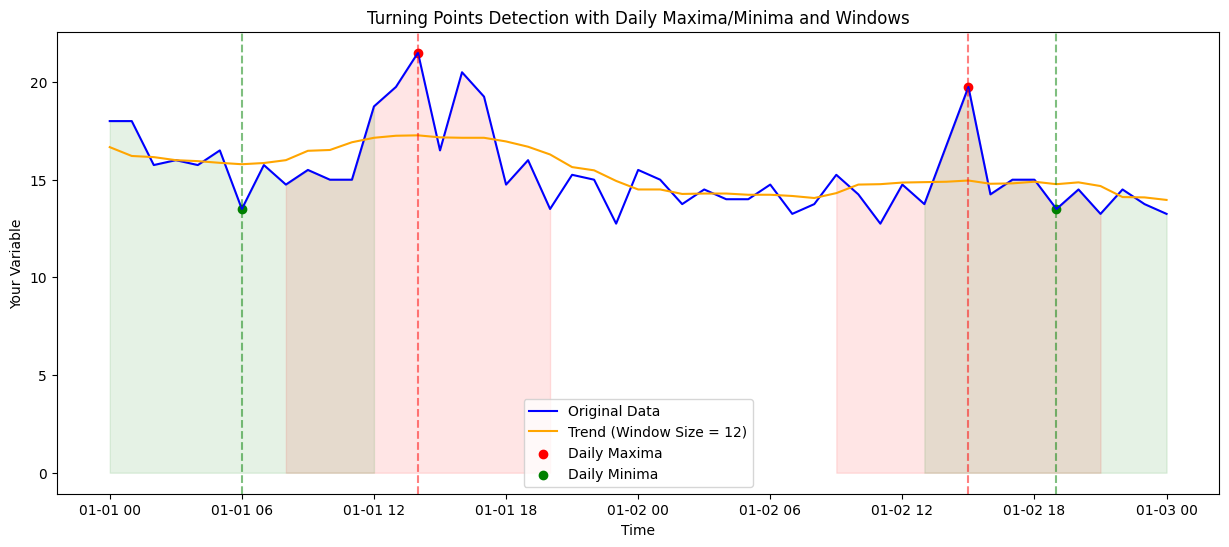

In [40]:
# Find max-min in one day (Final)

df1 = df1.set_index(pd.to_datetime(df1.index))

def detect_daily_turning_points(df, var, window_size=24):
    # 시계열 분해 및 trend 추출
    trend = df[var].rolling(window=window_size, min_periods=1, center=True).mean()

    # 변곡점 찾기
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    local_minima = argrelextrema(trend.values, np.less)[0]

    # 일별로 그룹화
    df.index = pd.to_datetime(df.index)
    df.loc[:, 'date'] = df.index.date 
    
    grouped_maxima = df.iloc[local_maxima].groupby('date')[var].idxmax().reset_index(drop=True)
    grouped_minima = df.iloc[local_minima].groupby('date')[var].idxmin().reset_index(drop=True)

    # grouped_maxima = df.iloc[local_maxima].groupby('date').apply(lambda x: x.loc[x[var].idxmax()])
    # grouped_minima = df.iloc[local_minima].groupby('date').apply(lambda x: x.loc[x[var].idxmin()])

    # 그래프 표시
    plt.figure(figsize=(15, 6))
    plt.plot(df.index, df[var], label='Original Data', color='blue')
    plt.plot(df.index, trend, label=f'Trend (Window Size = {window_size})', color='orange')
    
    window_size_hours = window_size  # 원하는 시간 간격을 설정하세요.
    
       # 변곡점 구간 표시 및 주변 데이터 표시
    for date in grouped_maxima:
        max_date = pd.to_datetime(date)
        window_start = max_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = max_date + pd.Timedelta(hours=window_size_hours / 2)
        plt.axvline(x=max_date, color='red', linestyle='--', alpha=0.5)
        plt.fill_between(df.index, 0, df[var], where=(df.index >= window_start) & (df.index <= window_end),
                            color='red', alpha=0.1)

    for date in grouped_minima:
        min_date = pd.to_datetime(date)
        window_start = min_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
        plt.axvline(x=min_date, color='green', linestyle='--', alpha=0.5)
        plt.fill_between(df.index, 0, df[var], where=(df.index >= window_start) & (df.index <= window_end),
                            color='green', alpha=0.1)
    """                          
   # 변곡점 구간 표시
    for date in grouped_maxima.index:
        max_date = pd.to_datetime(date)
        if max_date in df.index:
            plt.axvline(x = max_date, color = 'red', linestyle = '--', alpha = 0.5)
            window_start = max_date - pd.Timedelta(hours=window_size_hours / 2)
            window_end = max_date + pd.Timedelta(hours=window_size_hours / 2)
            plt.fill_between(df.index, 0, df[var], where=(df.index >= window_start) & (df.index <= window_end),
                             color='red', alpha=0.1)

    for date in grouped_minima.index:
        min_date = pd.to_datetime(date)
        if min_date in df.index:
            plt.axvline(x = min_date, color = 'green', linestyle = '--', alpha = 0.5)
            window_start = min_date - pd.Timedelta(hours=window_size_hours / 2)
            window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
            plt.fill_between(df.index, 0, df[var], where=(df.index >= window_start) & (df.index <= window_end),
                             color='green', alpha=0.1)
    
    """
    plt.scatter(grouped_maxima, df.loc[grouped_maxima, var], marker='o', color='red', label='Daily Maxima')
    plt.scatter(grouped_minima, df.loc[grouped_minima, var], marker='o', color='green', label='Daily Minima')

    plt.title('Turning Points Detection with Daily Maxima/Minima and Windows')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
detect_daily_turning_points(df1["2020-01-01 00:00:00": "2020-01-03 00:00:00"], 'b002_raw', window_size=12)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_52123/405526212.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[:, 'date'] = df.index.date


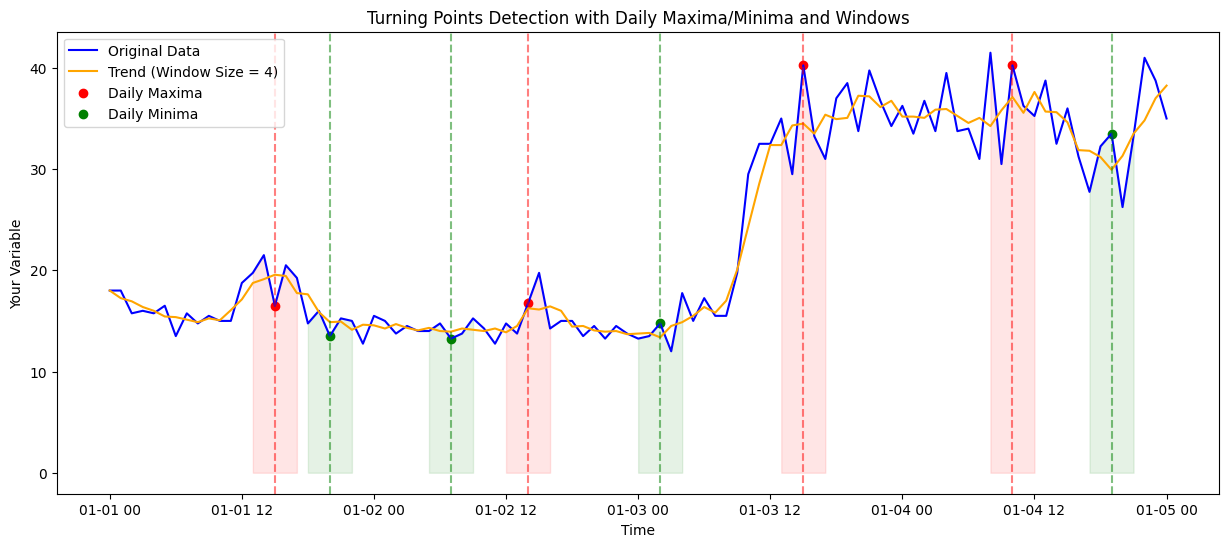

In [45]:
detect_daily_turning_points(df1["2020-01-01 00:00:00": "2020-01-05 00:00:00"], 'b002_raw', window_size = 4)

Maxima Times:
Date/Time
2020-01-01 00:00:00    18.00
2020-01-02 15:00:00    19.75
2020-01-04 22:00:00    41.00
2020-01-04 22:00:00    41.00
2020-01-06 12:00:00    50.00
                       ...  
2023-04-28 15:00:00    47.75
2023-04-29 14:00:00    46.50
2023-05-01 11:00:00    35.00
2023-05-02 15:00:00    36.75
2023-05-03 18:00:00    37.00
Name: b002_raw, Length: 912, dtype: float64

Minima Times:
Date/Time
2020-01-01 20:00:00    13.50
2020-01-02 11:00:00    12.75
2020-01-04 20:00:00    26.25
2020-01-04 21:00:00    33.25
2020-01-07 02:00:00    27.75
                       ...  
2023-04-29 06:00:00    28.25
2023-04-30 23:00:00    28.25
2023-05-01 23:00:00    27.25
2023-05-02 05:00:00    25.50
2023-05-02 23:00:00    28.50
Name: b002_raw, Length: 903, dtype: float64


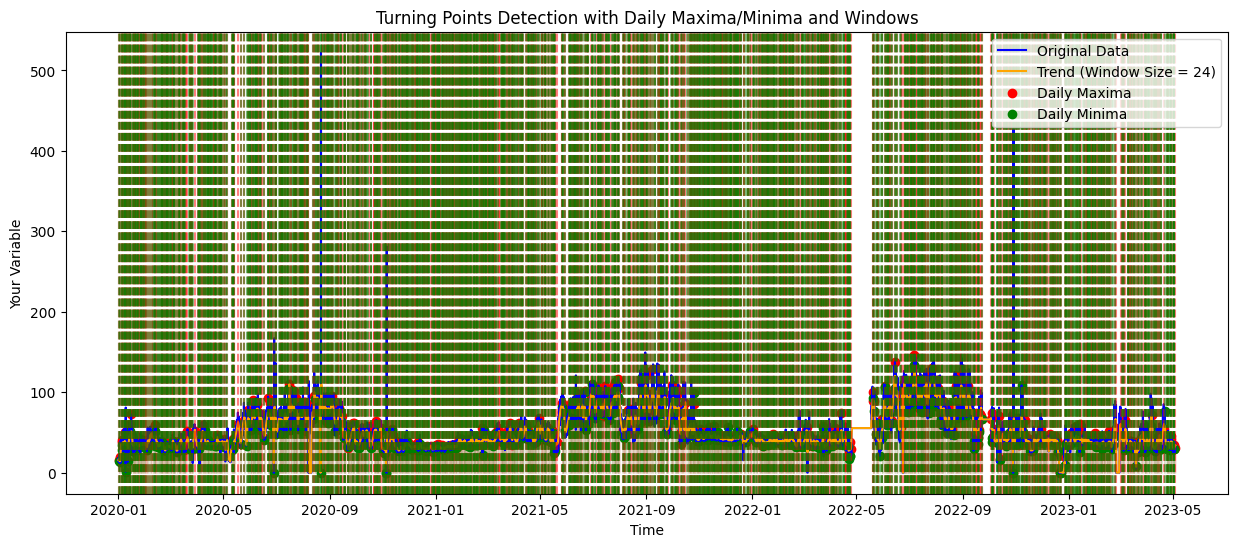

In [46]:
def detect_daily_turning_points(df, window_size=24, window_size_hours=6):
    # 시계열 분해 및 trend 추출
    trend = df['b002_raw'].rolling(window=window_size, min_periods=1, center=True).mean()

    # 변곡점 찾기
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    local_minima = argrelextrema(trend.values, np.less)[0]

    # 일별로 그룹화
    df.loc[:, 'date'] = df.index.date  # Use .loc to create 'date' column

    grouped_maxima = df.iloc[local_maxima].groupby('date')['b002_raw'].idxmax().reset_index(drop=True)
    grouped_minima = df.iloc[local_minima].groupby('date')['b002_raw'].idxmin().reset_index(drop=True)

    # 각 최댓값과 최솟값의 시간대 비교를 위한 리스트 초기화
    maxima_times = []
    minima_times = []

    # 변곡점 구간 표시 및 주변 데이터 표시
    for date in grouped_maxima:
        max_date = pd.to_datetime(date)
        window_start = max_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = max_date + pd.Timedelta(hours=window_size_hours / 2)
        maxima_times.append(df[(df.index >= window_start) & (df.index <= window_end)]['b002_raw'].idxmax())

    for date in grouped_minima:
        min_date = pd.to_datetime(date)
        window_start = min_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
        minima_times.append(df[(df.index >= window_start) & (df.index <= window_end)]['b002_raw'].idxmin())

    # 각 최댓값과 최솟값에 해당하는 시간대 출력
    print("Maxima Times:")
    print(df.loc[maxima_times, 'b002_raw'])

    print("\nMinima Times:")
    print(df.loc[minima_times, 'b002_raw'])

    # 그래프 표시
    plt.figure(figsize=(15, 6))
    plt.plot(df.index, df['b002_raw'], label='Original Data', color='blue')
    plt.plot(df.index, trend, label=f'Trend (Window Size = {window_size})', color='orange')

    for date in grouped_maxima:
        max_date = pd.to_datetime(date)
        window_start = max_date - pd.Timedelta(hours = window_size_hours / 2)
        window_end = max_date + pd.Timedelta(hours = window_size_hours / 2)
        plt.axvline(x = max_date, color = 'red', linestyle = '--', alpha = 0.5)
        plt.fill_between(df.index, 0, df['b002_raw'], where=(df.index >= window_start) & (df.index <= window_end),
                         color = 'red', alpha = 0.1)

    for date in grouped_minima:
        min_date = pd.to_datetime(date)
        window_start = min_date - pd.Timedelta(hours = window_size_hours / 2)
        window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
        plt.axvline(x=min_date, color='green', linestyle='--', alpha=0.5)
        plt.fill_between(df.index, 0, df['b002_raw'], where=(df.index >= window_start) & (df.index <= window_end),
                         color='green', alpha=0.1)

    plt.scatter(grouped_maxima, df.loc[grouped_maxima, 'b002_raw'], marker='o', color='red', label='Daily Maxima')
    plt.scatter(grouped_minima, df.loc[grouped_minima, 'b002_raw'], marker='o', color='green', label='Daily Minima')

    plt.title('Turning Points Detection with Daily Maxima/Minima and Windows')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
# detect_daily_turning_points(df1, window_size=24, window_size_hours=6)

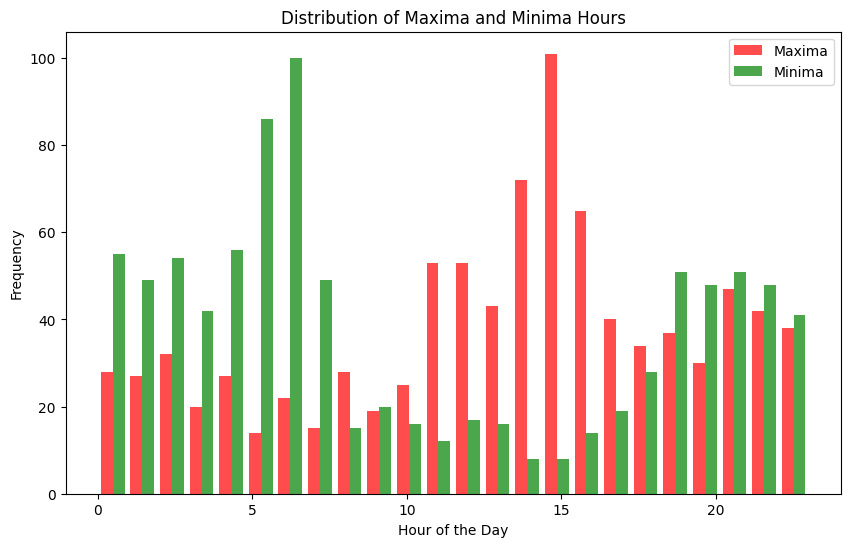

In [86]:
def detect_daily_turning_points(df, var, window_size=24, window_size_hours=6):
   
    # 시계열 분해 및 trend 추출
    trend = df[var].rolling(window=window_size, min_periods=1, center=True).mean()

    # 변곡점 찾기
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    local_minima = argrelextrema(trend.values, np.less)[0]

    # 일별로 그룹화
    df.loc[:, 'date'] = df.index.date  # Use .loc to create 'date' column

    grouped_maxima = df.iloc[local_maxima].groupby('date')[var].idxmax().reset_index(drop=True)
    grouped_minima = df.iloc[local_minima].groupby('date')[var].idxmin().reset_index(drop=True)

    # 각 최댓값과 최솟값의 시간대 비교를 위한 리스트 초기화
    maxima_times = []
    minima_times = []

    # 변곡점 구간 표시 및 주변 데이터 표시
    for date in grouped_maxima:
        max_date = pd.to_datetime(date)
        window_start = max_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = max_date + pd.Timedelta(hours=window_size_hours / 2)
        maxima_times.append(df[(df.index >= window_start) & (df.index <= window_end)][var].idxmax())

    for date in grouped_minima:
        min_date = pd.to_datetime(date)
        window_start = min_date - pd.Timedelta(hours=window_size_hours / 2)
        window_end = min_date + pd.Timedelta(hours=window_size_hours / 2)
        minima_times.append(df[(df.index >= window_start) & (df.index <= window_end)][var].idxmin())

    # 각 최댓값과 최솟값에 해당하는 시간대를 추출
    maxima_hours = df.loc[maxima_times, var].index.hour
    minima_hours = df.loc[minima_times, var].index.hour

    # 그래프 표시
    plt.figure(figsize=(10, 6))
    plt.hist([maxima_hours, minima_hours], bins=24, alpha=0.7, color=['red', 'green'], label=['Maxima', 'Minima'])
    plt.title('Distribution of Maxima and Minima Hours')
    plt.xlabel('Hour of the Day')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
detect_daily_turning_points(df1, 'b002_raw', window_size=24, window_size_hours=6)

### Calculate Attention score for window

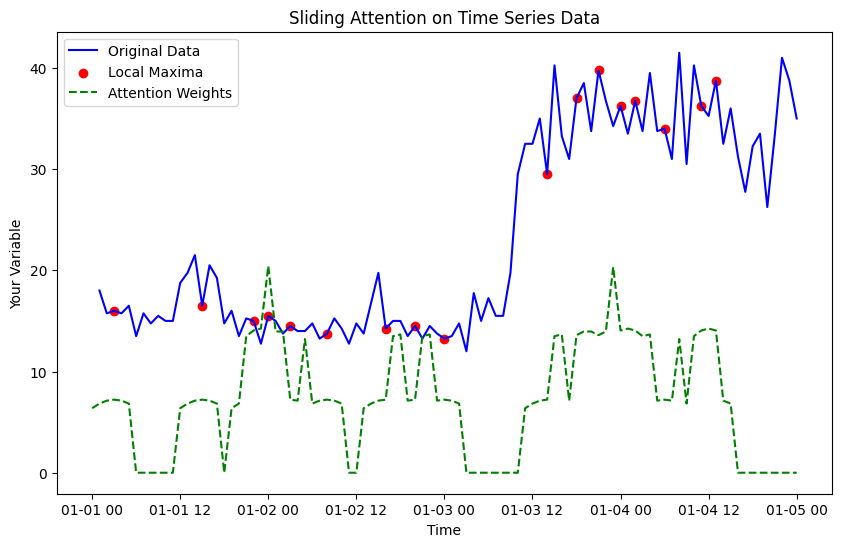

In [29]:
# apply attention for window

def sliding_attention(df, var, window_size = 24, sigma = 6):
    
    # 시계열 데이터에서의 변곡점 찾기
    trend = df[var].rolling(window = window_size, min_periods = 1, center = True).mean()
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    
    # Attention을 적용할 sliding window 설정
    attention_weights = np.zeros(len(df))
    
    for max_index in local_maxima:
        window_start = max(0, max_index - window_size//2)
        window_end = min(len(df), max_index + window_size//2)
        window_data = df[var].iloc[window_start:window_end]
        
        # Gaussian 함수를 사용하여 각 데이터 포인트에 대한 가중치 계산
        weights = np.exp(-0.5 * ((np.arange(len(window_data)) - window_size//2) / sigma) ** 2)
        
        # Attention을 현재 sliding window에 적용
        attention_weights[window_start:window_end] += weights / np.sum(weights)
    
    # Attention이 적용된 데이터로 그래프 표시
    plt.figure(figsize = (12, 6))
    plt.plot(df.index, df[var], label = 'Original Data', color = 'blue')
    plt.scatter(df.index[local_maxima], df[var].iloc[local_maxima], color = 'red', marker = 'o', label = 'Local Maxima')
    plt.plot(df.index, attention_weights * df[var].max(), label = 'Attention Weights', color = 'green', linestyle = '--')
    
    plt.title('Sliding Attention on Time Series Data')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
sliding_attention(df1["2020-01-01 00:00:00": "2020-01-05 00:00:00"], 'b002_raw', window_size = 6, sigma=6)


In [ ]:
# Attention + LSTM-AE

def sliding_attention_lstm_ae(df, var, window_size=24, sigma=6, latent_dim=8):
    # 정규화
    scaler = MinMaxScaler()
    normalized_data = scaler.fit_transform(df[[var]])
    
    # 시계열 데이터에서의 변곡점 찾기
    trend = df[var].rolling(window = window_size, min_periods=1, center=True).mean()
    local_maxima = argrelextrema(trend.values, np.greater)[0]
    
    # Attention을 적용할 sliding window 설정
    attention_weights = np.zeros(len(df))
    
    for max_index in local_maxima:
        window_start = max(0, max_index - window_size//2)
        window_end = min(len(df), max_index + window_size//2)
        window_data = normalized_data[window_start:window_end]
        
        # Gaussian 함수를 사용하여 각 데이터 포인트에 대한 가중치 계산
        weights = np.exp(-0.5 * ((np.arange(len(window_data)) - window_size//2) / sigma) ** 2)
        
        # Attention을 현재 sliding window에 적용
        attention_weights[window_start:window_end] += weights / np.sum(weights)
    
    # LSTM-AE 모델 정의
    model = Sequential()
    model.add(LSTM(latent_dim, activation='relu', input_shape=(len(df), 1)))
    model.add(RepeatVector(len(df)))
    model.add(LSTM(1, activation='relu', return_sequences=True))
    model.add(TimeDistributed(Dense(1)))
    model.compile(optimizer='adam', loss='mse')

    # Attention Weights를 입력 데이터에 추가
    input_data = np.expand_dims(np.concatenate([normalized_data, np.expand_dims(attention_weights, axis=1)], axis=1), axis=0)

    # 모델 학습
    model.fit(input_data, input_data, epochs=50, batch_size=1, verbose=0)

    # 예측
    reconstructed_data = model.predict(input_data)

    # 시각화
    plt.figure(figsize=(12, 6))
    plt.plot(df.index, scaler.inverse_transform(normalized_data)[:, 0], label='Original Data', color='blue')
    plt.plot(df.index, scaler.inverse_transform(reconstructed_data[0, :, :])[:, 0], label='Reconstructed Data', color='orange')
    plt.plot(df.index, attention_weights * df[var].max(), label='Attention Weights', color='green', linestyle='--')

    plt.title('Sliding Attention on LSTM-AE for Time Series Data')
    plt.xlabel('Time')
    plt.ylabel('Your Variable')
    plt.legend()
    plt.show()

# 예시: df1을 사용하여 함수 호출
sliding_attention_lstm_ae(df1, var, window_size=24, sigma=6, latent_dim=8)


In [49]:
df1 = df1.drop(['date'], axis = 1)

915/915 [==============================] - 1s 907us/step


IndexError: index 1 is out of bounds for axis 2 with size 1

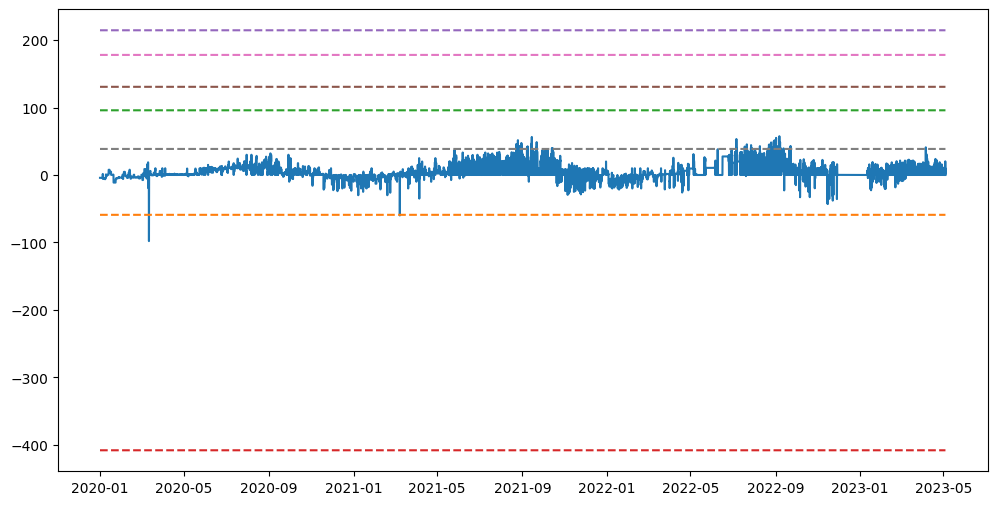

In [83]:
### Modeling multivariate 

def sliding_attention_lstm_ae_multivariate_dynamic(df, window_size=24, sigma=6, latent_dim=8, epoch = 10):
    # 정규화
    scaler = MinMaxScaler()
    normalized_data = scaler.fit_transform(df.values)

    # 시계열 데이터에서의 변곡점 찾기
    trend = df.iloc[:, 0].rolling(window=window_size, min_periods=1, center=True).mean()
    local_maxima = argrelextrema(trend.values, np.greater)[0]

    # Attention을 적용할 sliding window 설정
    attention_weights = np.zeros(len(df))

    for max_index in local_maxima:
        window_start = max(0, max_index - window_size//2)
        window_end = min(len(df), max_index + window_size//2)
        window_data = normalized_data[window_start:window_end, :]

        # Gaussian 함수를 사용하여 각 데이터 포인트에 대한 가중치 계산
        weights = np.exp(-0.5 * ((np.arange(len(window_data)) - window_size//2) / sigma) ** 2)

        # Attention을 현재 sliding window에 적용
        attention_weights[window_start:window_end] += weights / np.sum(weights)

    # LSTM-AE 모델 정의
    model = Sequential()
    model.add(LSTM(latent_dim, activation='relu', input_shape=(normalized_data.shape[1], 1)))
    model.add(RepeatVector(normalized_data.shape[1]))
    model.add(LSTM(1, activation='relu', return_sequences=True))
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse')

    # Attention Weights를 입력 데이터에 추가
    input_data = normalized_data[:, :, np.newaxis]
    
    # 모델 학습
    model.fit(input_data, normalized_data[:, :, np.newaxis], epochs = epoch, batch_size=1, verbose=1)

    # 예측
    reconstructed_data = model.predict(input_data)

    # 시각화
    plt.figure(figsize=(12, 6))
    for i in range(normalized_data.shape[1]):
        original_variable = scaler.inverse_transform(normalized_data)[:, i]
        reconstructed_variable = scaler.inverse_transform(reconstructed_data[:, :, i])
        plt.plot(df.index, original_variable, label=f'Original Variable {i+1}')
        plt.plot(df.index, reconstructed_variable, linestyle='--', label=f'Reconstructed Variable {i+1}')

    plt.plot(df.index, attention_weights * np.max(df.values), label='Attention Weights', color='black', linestyle='--')
    plt.title('Sliding Attention on LSTM-AE for Multivariate Time Series Data')
    plt.xlabel('Time')
    plt.ylabel('Normalized Values')
    plt.legend()
    plt.show()


# 예시: df1을 사용하여 함수 호출 (다변량 변수 예시)
sliding_attention_lstm_ae_multivariate_dynamic(df1, window_size=24, sigma=6, latent_dim=8, epoch = 1)